<a href="https://colab.research.google.com/github/ixrlts/data-analytics-case-studies/blob/main/projects/diamonds/01_color_vs_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('diamonds')
df.head(10)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


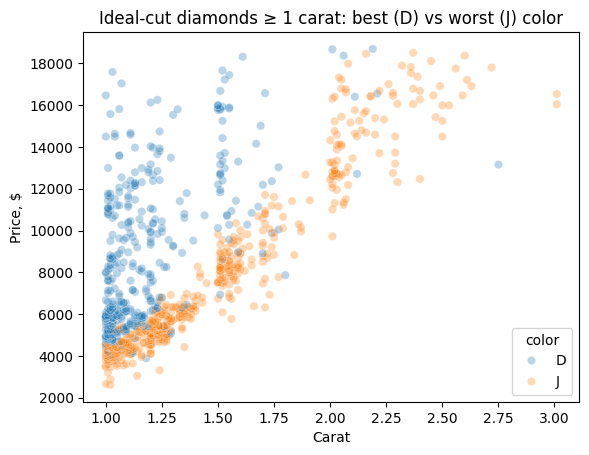

In [ ]:
big_ideal = df[(df['cut'] == 'Ideal') & (df['carat'] >= 1) & (df['color'].isin(['D', 'J']))].copy()
sns.scatterplot(data=big_ideal, x='carat', y='price', hue='color', hue_order=['D', 'J'], alpha=0.3)
plt.title('Ideal-cut diamonds ≥ 1 carat: best (D) vs worst (J) color')
plt.xlabel('Carat')
plt.ylabel('Price, $')
plt.show()

In [ ]:
big_ideal['price_per_carat'] = big_ideal['price'] / big_ideal['carat']
big_ideal.groupby('color', observed=True).agg(
    avg_price=('price', 'mean'),
    avg_carat=('carat', 'mean'),
    avg_ppc=('price_per_carat', 'mean')
).round(2)

,avg_price,avg_carat,avg_ppc
color,,,
D,8924.55,1.18,7487.65
J,7909.90,1.49,5018.87


Among ideal-cut diamonds ≥ 1 carat, D-colored stones cost about 50% more than J, average prices tend to look similar, because J-colored stones tend to be larger.